# 02 - XGBoost Training
Chronological split (earlier 80% train, later 20% test) - random split in time series causes data leakage.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from backend import preprocessing as pp, model as tm

In [2]:
clean_df, _ = pp.clean(pp.load_raw())
features = pp.build_features(clean_df)
train, test = pp.split_chronological(features, 0.2)
print(len(train), len(test))
print('Train:', train.DateTime.min(), '->', train.DateTime.max())
print('Test :', test.DateTime.min(), '->', test.DateTime.max())

9060 2268
Train: 2024-01-08 00:00:00 -> 2024-04-11 08:00:00
Test : 2024-04-11 09:00:00 -> 2024-05-04 23:00:00


In [3]:
model = tm.make_regressor()
model.fit(train[pp.FEATURE_COLUMNS], train[pp.TARGET])
pred = np.clip(model.predict(test[pp.FEATURE_COLUMNS]), 0, None)
tm.score(test[pp.TARGET], pred)

{'mae': 3.5763332843780518,
 'rmse': 4.527219255527842,
 'r2': 0.7956679463386536}

## Feature importance

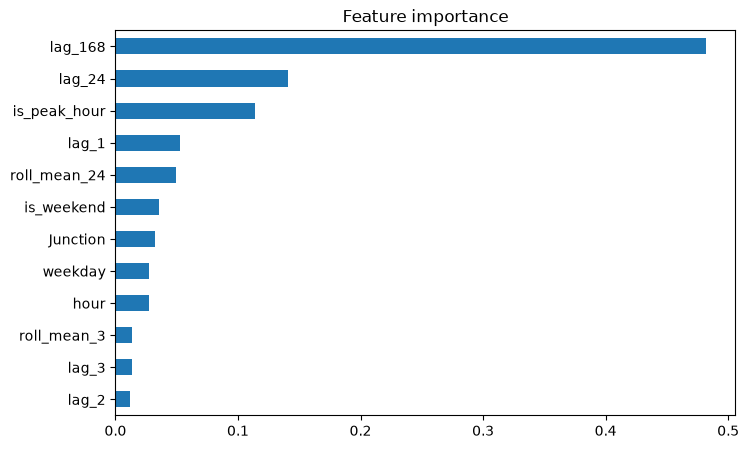

In [4]:
imp = pd.Series(model.feature_importances_, index=pp.FEATURE_COLUMNS).sort_values()
imp.plot(kind='barh', figsize=(8,5), title='Feature importance'); plt.show()

## Final model save karo (models/traffic_xgb_model.joblib + metadata)

In [5]:
meta = tm.train_and_save(features)
meta['metrics']

{'xgboost': {'mae': 3.5763332843780518,
  'rmse': 4.527219255527842,
  'r2': 0.7956679463386536},
 'baseline_last_hour': {'mae': 6.036596119929453,
  'rmse': 7.928499928177531,
  'r2': 0.37330614427380915},
 'baseline_same_hour_yesterday': {'mae': 5.3619929453262785,
  'rmse': 6.923651410463666,
  'r2': 0.52209258191888}}